In [ ]:
# Paths: set DATA_DIR / OUTPUT_DIR as environment variables, or edit the defaults below.
import os
DATA_DIR = os.environ.get("DATA_DIR", "../data")


In [1]:
!pip install ultralytics -q

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from torchvision import models, transforms
from ultralytics import YOLO
pass  # Colab only: from google.colab import drive

pass  # Colab only: drive.mount('/content/drive')

ROOT = Path(DATA_DIR)

DETECTOR_PATH   = ROOT / '01_detection' / 'runs' / 'yolov8s' / 'weights' / 'best.pt'
CLASSIFIER_PATH = ROOT / '02_classification' / 'weights' / 'squeezenet_best.pt'

MATERIALS = ['glass', 'metal', 'misc', 'pottery']
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

detector = YOLO(str(DETECTOR_PATH))
object_class_names = detector.names
print("Detector loaded. Object classes:", list(object_class_names.values()))

# Rebuild the SqueezeNet structure, then load the trained weights.
classifier = models.squeezenet1_1(weights=None)
classifier.classifier[1] = nn.Conv2d(512, len(MATERIALS), kernel_size=1)
classifier.num_classes = len(MATERIALS)
classifier.load_state_dict(torch.load(CLASSIFIER_PATH, map_location=device))
classifier = classifier.to(device)
classifier.eval()
print("Classifier loaded. Material classes:", MATERIALS)

image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

print("\nBoth models ready. Device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 4.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Mounted at /content/drive
Detector loaded. Object classes: ['Bangle', 'Closed_vessel', 'Lamp_burner', 'Misc', 'Open_vessel', 'Personal_ornament', 'Sprinkler', 'Vessel_fragment']
Classifier loaded. Material classes: ['glass', 'metal', 'misc', 'pottery']

Both models ready. Device: cuda


In [2]:
def classify_crop(crop_image):
    """Take a cropped PIL image, return (material, confidence)."""
    tensor = image_transform(crop_image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = classifier(tensor)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted_index = probabilities.max(dim=1)
    material = MATERIALS[predicted_index.item()]
    return material, confidence.item()


def run_pipeline(image_path, conf_threshold=0.25, show=True):
    """Detect artefacts, classify each one's material, draw the result."""
    original = Image.open(image_path).convert('RGB')
    detections = detector.predict(str(image_path), conf=conf_threshold, verbose=False)[0]

    results = []
    for box in detections.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        object_type = object_class_names[int(box.cls)]
        detect_conf = float(box.conf)

        crop = original.crop((x1, y1, x2, y2))
        material, material_conf = classify_crop(crop)

        results.append({'object_type': object_type, 'detect_conf': detect_conf,
                        'material': material, 'material_conf': material_conf,
                        'box': (x1, y1, x2, y2)})

    if show:
        fig, ax = plt.subplots(figsize=(10, 8))
        ax.imshow(original)
        ax.axis('off')
        for r in results:
            x1, y1, x2, y2 = r['box']
            label = f"{r['object_type']} / {r['material']}"
            ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor='red', linewidth=2))
            ax.text(x1, max(y1 - 5, 0), label, color='white', fontsize=10,
                    bbox=dict(facecolor='red', alpha=0.7, pad=1))
        plt.title("End-to-end: object type / material")
        plt.tight_layout()
        plt.show()

    if results:
        print("Detected artefacts:")
        for r in results:
            print(f"  {r['object_type']} (det {r['detect_conf']:.2f})"
                  f"  ->  {r['material']} (mat {r['material_conf']:.2f})")
    else:
        print("No artefacts detected above the confidence threshold.")

    return results

Saving 1.JPG to 1.JPG
Image: 1.JPG


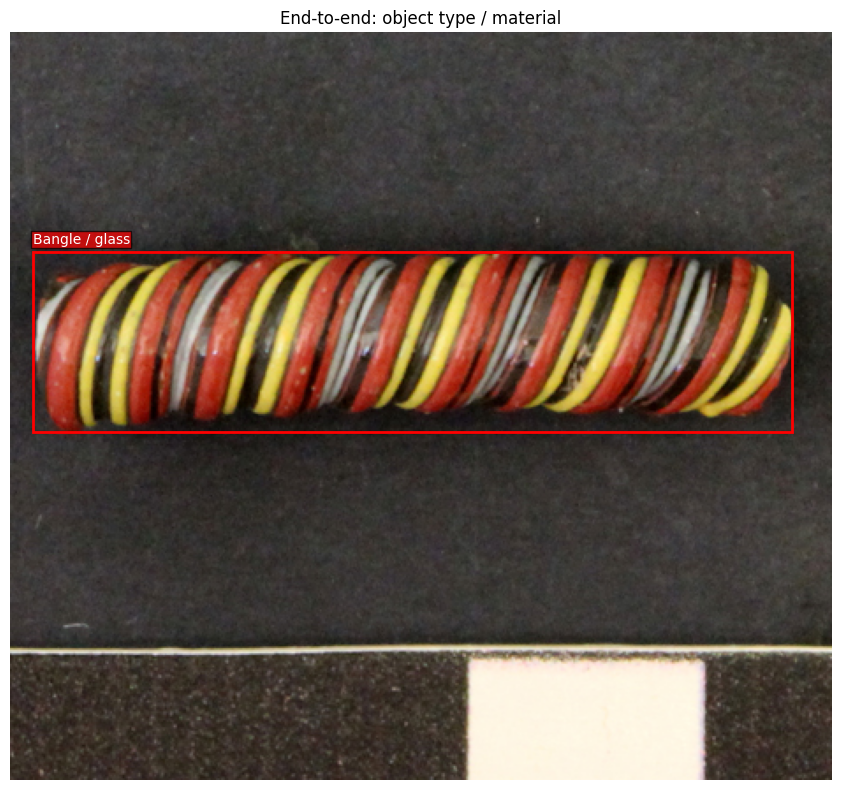

Detected artefacts:
  Bangle (det 0.92)  ->  glass (mat 1.00)



In [3]:
pass  # Colab only: from google.colab import files

uploaded = files.upload()

for fname in uploaded:
    print(f"Image: {fname}")
    run_pipeline(fname)
    print()